# 🫀 CardioRisk Studio — Prédiction de la présence d'une maladie cardiaque (Heart Disease UCI)

**Données** : UCI Heart Disease (id 45), Janosi, Steinbrunn, Pfisterer & Detrano (1989), DOI 10.24432/C52P4X, licence **CC BY 4.0** (citation obligatoire). Copie Kaggle : `redwankarimsony/heart-disease-data`.

**Avertissement** : projet pédagogique. Le modèle ne remplace pas un diagnostic médical.

**Plan** : **Partie A — Cadrage** (A1 Contexte · A2 Problématique · A3 Processus ML · A4 Attributs) puis **Partie B — Réalisation** (1 Chargement · 2 Compréhension des données · 3 Valeurs manquantes · 4 Variable cible · 5 Exploration et corrélation · 6 Train/Test split · 7 Préparation · 8 Modèles · 9 Évaluation · 10 Seuil · 11 Importance · 12 Export · 13 Conclusion)

**Mode d'emploi** : chaque cellule de code a **une seule tâche**, précédée d'une explication (*Tâche / Pourquoi*) et suivie d'une **interprétation** des résultats obtenus.

## Contexte du début de projet

**Projet :** CardioRisk Studio — prototype pédagogique d’aide à la décision pour le **pré-dépistage** (triage/priorisation) du risque de maladie coronarienne.

**Définitions simples :**
- **Dépistage** : repérer tôt les personnes potentiellement à risque pour les orienter vers des examens/avis médical.
- **Pré-dépistage / triage** : filtre rapide en amont pour décider qui doit être contrôlé en priorité. Ce n'est pas un diagnostic.
- **Diagnostic** : acte médical réalisé par un professionnel de santé ; ce projet ne remplace pas le diagnostic.

**Contexte métier :** les maladies cardiovasculaires sont un enjeu majeur. Les professionnels ont besoin d’outils qui aident à prioriser les patients à risque à partir de données cliniques/examens, sans remplacer le diagnostic médical.

**Objectif :** construire un pipeline ML reproductible (EDA, nettoyage, pipeline anti-fuite, modèles, évaluation, seuil de dépistage) et l’exposer dans une application Streamlit.

**Périmètre / données :** dataset Heart Disease UCI (920 observations, 16 colonnes avant préparation), cible binaire `num > 0`.

**Limites assumées :** données historiques multi-centres, valeurs manquantes importantes (`ca`, `thal`, `slope`), outil pédagogique uniquement — validation humaine obligatoire.


## Structure attendue (validation VIC) — où la trouver dans ce notebook

| Exigence VIC | Où dans le notebook |
|---|---|
| Contexte, objectifs, domaine | Début du projet / A1-A4 |
| Solutions existantes / limites | A3-A4, limites |
| Problème à résoudre | Problématique |
| Approche, valeur ajoutée, architecture/flux | Pipeline / schéma |
| Données : origine, description, nb observations, variables, prétraitement | Sections 1-4, 7 |
| Justification choix modèle, principe, paramètres | Sections 8, 10-11 |
| Matrice de corrélation + interprétation | Étude de corrélation |
| Résultats et indicateurs de performance | Section 9 + métriques R²/MAE/MSE |
| Interprétation R², MAE, MSE | Section métriques R²/MAE/MSE |
| Test nouvelles données, réel vs prédit, limites/perspectives | Section test final / prédiction manuelle |
| Résultats issus de l'implémentation | Toutes sorties exécutées |

> **Note :** R², MAE, MSE sont des métriques classiquement régressives. Le problème cardiaque est une **classification binaire**. Nous les calculons de manière transparente : (1) sur la probabilité prédite vs cible 0/1 (Brier-style) et (2) sur la classe prédite 0/1, avec interprétation prudente.


## A1. Contexte

Les maladies cardiovasculaires représentent un enjeu majeur de santé publique. Leur présence peut être associée à plusieurs facteurs : âge, sexe, pression artérielle, cholestérol, fréquence cardiaque, symptômes ressentis et résultats d'examens médicaux.

L'exploitation de données médicales permet d'étudier les relations entre ces facteurs et la présence d'une maladie cardiaque. Grâce au Machine Learning, on peut apprendre à partir de dossiers de patients pour construire un modèle de classification qui estime si un patient présente ou non une maladie cardiaque.

Le jeu de données **Heart Disease UCI** regroupe des données cliniques et des résultats d'examens de patients issus de **4 centres** (Cleveland, Hongrie, Suisse, VA Long Beach). Il comporte **303 patients** pour Cleveland seul et **environ 920** pour la version combinée (Kaggle).

## A2. Problématique

> **Peut-on exploiter les données cliniques et les résultats d'examens médicaux pour construire un modèle de Machine Learning capable de prédire la présence ou l'absence d'une maladie cardiaque chez un patient ?**

Il s'agit d'une **classification supervisée binaire** :

| Classe | Signification |
|:---:|---|
| 0 | Absence de maladie cardiaque (`num = 0`, sténose < 50 %) |
| 1 | Présence de maladie cardiaque (`num > 0`, sténose > 50 % d'au moins un vaisseau majeur) |

⚠️ Le modèle prédit **la présence d'une maladie dans les données** (diagnostic), et **non le risque de faire une crise cardiaque dans le futur**.

**Objectif général** : prédire la présence ou l'absence de maladie cardiaque à partir des caractéristiques cliniques, tout en identifiant les variables les plus associées à la maladie.

**Questions de recherche**
- **Q1** — Quels facteurs médicaux sont les plus associés à la maladie ? *(section 5, exploration et corrélation)*
- **Q2** — Quelles variables contribuent le plus à la prédiction ? *(section 11, importance)*
- **Q3** — Dans quelle mesure le ML distingue-t-il malades et non-malades ? *(section 9, évaluation)*
- **Q4** — Quel modèle est le plus performant ? *(section 8, comparaison)*
- **Q5** — Le modèle détecte-t-il efficacement les malades en limitant les **faux négatifs** ? *(section 10, rappel et seuil)*

Un **faux négatif** est un patient malade classé non malade : c'est l'erreur la plus coûteuse en contexte médical, d'où l'attention portée au **rappel**.

## A3. Schéma du processus de Machine Learning

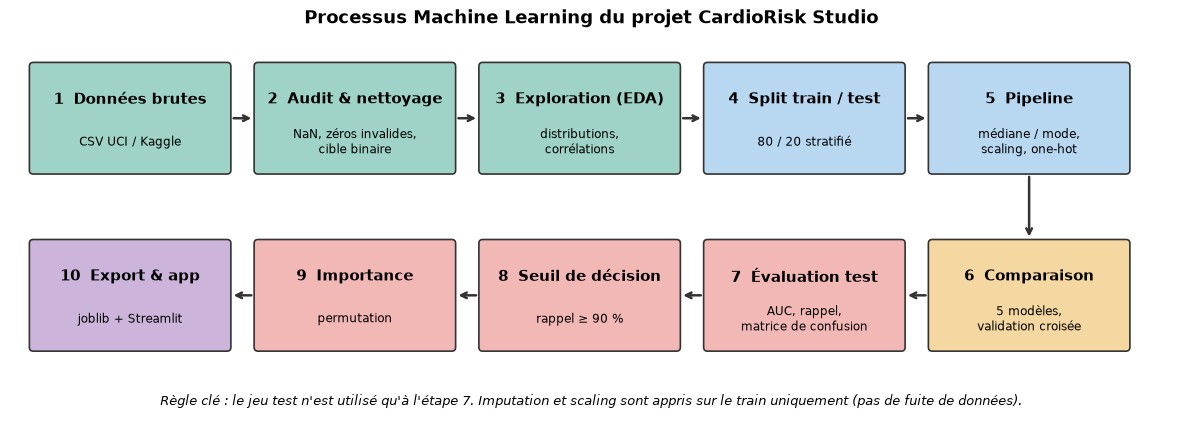

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    ("1  Données brutes", "CSV UCI / Kaggle"),
    ("2  Audit & nettoyage", "NaN, zéros invalides,\ncible binaire"),
    ("3  Exploration (EDA)", "distributions,\ncorrélations"),
    ("4  Split train / test", "80 / 20 stratifié"),
    ("5  Pipeline", "médiane / mode,\nscaling, one-hot"),
    ("6  Comparaison", "5 modèles,\nvalidation croisée"),
    ("7  Évaluation test", "AUC, rappel,\nmatrice de confusion"),
    ("8  Seuil de décision", "rappel ≥ 90 %"),
    ("9  Importance", "permutation"),
    ("10  Export & app", "joblib + Streamlit"),
]
colors = ["#9FD3C7", "#9FD3C7", "#9FD3C7", "#B8D8F2", "#B8D8F2", "#F5D7A1", "#F2B8B5", "#F2B8B5", "#F2B8B5", "#CDB4DB"]

fig, ax = plt.subplots(figsize=(15, 5.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 5.2); ax.axis("off")
w, h = 2.5, 1.35
pos = [(0.3 + i * 2.9, 3.4) for i in range(5)] + [(0.3 + (4 - i) * 2.9, 1.1) for i in range(5)]
for (x, y), (t, s), c in zip(pos, steps, colors):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=c, ec="#333", lw=1.2))
    ax.text(x + w/2, y + h*0.68, t, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w/2, y + h*0.27, s, ha="center", va="center", fontsize=8.5)
for i in range(9):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    if i < 4:   a, b = (x1 + w + 0.05, y1 + h/2), (x2 - 0.05, y2 + h/2)
    elif i == 4: a, b = (x1 + w/2, y1 - 0.05), (x2 + w/2, y2 + h + 0.05)
    else:       a, b = (x1 - 0.05, y1 + h/2), (x2 + w + 0.05, y2 + h/2)
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=1.8, color="#333"))
ax.text(7.5, 0.35, "Règle clé : le jeu test n'est utilisé qu'à l'étape 7. Imputation et scaling sont appris sur le train uniquement (pas de fuite de données).",
        ha="center", fontsize=9.5, style="italic")
plt.title("Processus Machine Learning du projet CardioRisk Studio", fontsize=13, weight="bold")
plt.show()

## A4. Attributs techniques du dataset

**13 variables explicatives (X)** et **1 variable cible (Y)**. Les noms suivent le fichier CSV du projet (version Kaggle) : la fréquence cardiaque maximale s'appelle `thalch` (elle s'appelle `thalach` dans UCI).

| Variable | Signification | Famille | Type | Valeurs / unité | Préparation dans le pipeline |
|---|---|---|---|---|---|
| `age` | Âge du patient | Démographique | Numérique | années | Aucune valeur manquante ; StandardScaler (imputation médiane prévue par le pipeline si besoin) |
| `sex` | Sexe enregistré | Démographique | Catégorielle binaire | Male / Female (UCI : 1 / 0) | Mode + One-Hot |
| `cp` | Type de douleur thoracique | Symptôme | Catégorielle nominale | typical angina, atypical angina, non-anginal, asymptomatic (UCI : 1 à 4) | Mode + One-Hot |
| `trestbps` | Tension artérielle systolique au repos (à l'admission) | Mesure clinique | Numérique | mmHg ; **0 = invalide → NaN** | Médiane + StandardScaler |
| `chol` | Cholestérol sérique | Biologie | Numérique | mg/dl ; **0 = invalide → NaN** | Médiane + StandardScaler |
| `fbs` | Glycémie à jeun > 120 mg/dl | Biologie | Catégorielle binaire | True / False | Mode + One-Hot |
| `restecg` | Résultat de l'ECG au repos | Examen | Catégorielle nominale | normal, st-t abnormality, lv hypertrophy (UCI : 0 à 2) | Mode + One-Hot |
| `thalch` | Fréquence cardiaque maximale atteinte à l'effort | Test d'effort | Numérique | battements / min | Médiane + StandardScaler |
| `exang` | Angine provoquée par l'effort | Symptôme / test d'effort | Catégorielle binaire | True / False | Mode + One-Hot |
| `oldpeak` | Dépression du segment ST à l'effort par rapport au repos | Test d'effort (ECG) | Numérique | décimal, peut être négatif | Médiane + StandardScaler |
| `slope` | Pente du segment ST au pic de l'effort | Test d'effort (ECG) | Catégorielle nominale | upsloping, flat, downsloping (UCI : 1 à 3) | Mode + One-Hot |
| `ca` | Nombre de vaisseaux majeurs colorés à la fluoroscopie | Imagerie (invasive) | Numérique discrète | 0 à 3 ; **0 est une vraie valeur** | Médiane + indicateur de manquant + StandardScaler |
| `thal` | Résultat du test de perfusion (thallium) | Imagerie | Catégorielle nominale | normal, fixed defect, reversable defect (UCI : 3, 6, 7) | Mode + One-Hot |

**Variable cible**

| Variable | Valeurs d'origine | Transformation | Rôle |
|---|---|---|---|
| `num` | 0 = pas de sténose > 50 % ; 1 à 4 = sténose > 50 % (gravité croissante) | `target = (num > 0)` → 0 / 1 | Y à prédire (exclue de X) |

**Points d'attention**
- Les variables catégorielles codées par des chiffres (`cp`, `restecg`, `slope`, `thal`) sont des **groupes, pas des quantités** → One-Hot.
- `ca` et `thal` sont très incomplètes dans la version combinée (plus de 50 % hors Cleveland) : l'imputation pèse fortement sur les résultats.
- `ca`, `thal`, `oldpeak`, `thalch` proviennent d'examens spécialisés ou invasifs : ils sont peu disponibles lors d'un dépistage en amont.
- Colonnes `id` et `dataset` (centre d'origine) exclues des prédicteurs pour éviter un biais.

# Partie B — Réalisation

## 1. Chargement des données

**Tâche** : importer les bibliothèques.
**Pourquoi** : `pandas` manipule les tableaux, `numpy` fait les calculs, `matplotlib` et `seaborn` dessinent les graphiques.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

**Tâche** : charger le fichier CSV dans un tableau `df` (DataFrame) et afficher sa taille.
**Pourquoi** : c'est le point de départ : on ne peut rien analyser avant d'avoir les données en mémoire.

In [3]:
URL = "https://raw.githubusercontent.com/bennoomenfaker/cardiorisk-studio/main/heart_disease_uci.csv"
df = pd.read_csv(URL)     # ou : pd.read_csv("heart_disease_uci.csv") si le fichier est en local
df.shape

(920, 16)

**🔎 Interprétation** : `(920, 16)` = **920 patients** (lignes) et **16 colonnes** : `id`, `dataset` (centre d'origine), les **13 variables explicatives**, et `num` (le diagnostic, la cible).

**Tâche** : afficher les 5 premières lignes avec `head()`.
**Pourquoi** : vérifier visuellement que le fichier est bien lu (bons noms de colonnes, bon format).

In [4]:
df.head() 


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [5]:
df.tail()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0
919,920,62,Male,VA Long Beach,atypical angina,120.0,254.0,False,lv hypertrophy,93.0,True,0.0,NaN,NaN,NaN,1


**🔎 Interprétation** : chaque ligne est **un patient**. On voit un mélange de nombres (`age`, `chol`) et de textes (`Male`, `typical angina`). Les cases vides apparaissent comme `NaN` (valeur manquante).

## 2. Compréhension des données

**Tâche** : afficher la fiche technique du tableau avec `info()`.
**Pourquoi** : `info()` donne, pour chaque colonne, son **type** (nombre, texte…) et le **nombre de valeurs non vides**. C'est le premier contrôle qualité : repérer un mauvais type ou des valeurs manquantes.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


**🔎 Interprétation**
- Le tableau compte **920 lignes**. Une colonne avec moins de 920 « non-null » contient des valeurs manquantes.
- **Colonnes complètes** : `id`, `age`, `sex`, `dataset`, `cp`, `num`.
- **Colonnes très incomplètes** : `ca` (309 valeurs seulement), `thal` (434), `slope` (611).
- **Types** : `float64` pour les mesures, `str` pour les catégories. `fbs` et `exang` sont en `object` car elles mélangent `True`, `False` et des vides : on les traitera comme des catégories.
- **Conclusion** : les données sont hétérogènes, un nettoyage est nécessaire avant de modéliser.

**Tâche** : résumer les colonnes **numériques** avec `describe()`.
**Pourquoi** : `describe()` donne pour chaque variable le nombre de valeurs (`count`), la moyenne (`mean`), l'écart-type (`std`), le minimum, les quartiles (25 %, 50 % = médiane, 75 %) et le maximum. On s'en sert pour repérer des **valeurs impossibles**, des **valeurs extrêmes** et comparer **moyenne et médiane**.

In [7]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


**🔎 Interprétation**
- **`age`** : de 28 à 77 ans, moyenne 53,5 ans : des adultes d'âge moyen.
- **`count`** : `ca` n'a que 309 valeurs sur 920 (les deux tiers manquent).
- **`chol` : le minimum est 0**, ce qui est impossible pour un cholestérol. Ces zéros tirent la moyenne (199) **sous la médiane (223)**. Ce sont des valeurs manquantes déguisées, à corriger (section 3).
- **`trestbps`** : minimum 0 également (1 patient) : même problème.
- **`oldpeak`** : minimum négatif (−2,6). C'est médicalement possible, **on ne le supprime pas**.
- **`thalch`** (60 à 202) et **`ca`** (0 à 3) sont cohérents.
- `id` (simple numéro) et `num` (la cible, de 0 à 4) apparaissent ici mais ne sont pas des mesures cliniques.

**Tâche** : résumer les colonnes **texte** avec `describe(include="object")`.
**Pourquoi** : pour les catégories, on regarde le nombre de modalités (`unique`), la plus fréquente (`top`) et son effectif (`freq`).

In [8]:
df.describe(include="object")

/tmp/ipykernel_229905/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,sex,dataset,cp,fbs,restecg,exang,slope,thal
count,920,920,920,830,918,865,611,434
unique,2,4,4,2,3,2,3,3
top,Male,Cleveland,asymptomatic,False,normal,False,flat,normal
freq,726,304,496,692,551,528,345,196


**🔎 Interprétation**
- **`sex`** : 2 modalités, `Male` = 726 patients sur 920 (79 %) : l'échantillon est **très masculin**.
- **`dataset`** : 4 centres, `Cleveland` est le plus gros (304 patients).
- **`cp`** : la douleur thoracique la plus fréquente est `asymptomatic` (496 patients, 54 %).
- **`thal`** : seulement 434 valeurs (plus de la moitié manque), **`slope`** : 611.

**Tâche** : lister toutes les valeurs de chaque variable catégorielle avec leur effectif.
**Pourquoi** : détecter les fautes de frappe, les catégories rares et visualiser les valeurs manquantes (`nan`).

In [9]:
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]:
    print(col, "->", df[col].value_counts(dropna=False).to_dict())

sex -> {'Male': 726, 'Female': 194}
cp -> {'asymptomatic': 496, 'non-anginal': 204, 'atypical angina': 174, 'typical angina': 46}
fbs -> {False: 692, True: 138, nan: 90}
restecg -> {'normal': 551, 'lv hypertrophy': 188, 'st-t abnormality': 179, nan: 2}
exang -> {False: 528, True: 337, nan: 55}
slope -> {'flat': 345, nan: 309, 'upsloping': 203, 'downsloping': 63}
thal -> {nan: 486, 'normal': 196, 'reversable defect': 192, 'fixed defect': 46}


**🔎 Interprétation**
- Les catégories sont **propres** : pas de doublon d'écriture ni de faute.
- Valeurs manquantes visibles : `thal` 486, `slope` 309, `fbs` 90, `exang` 55, `restecg` 2.
- `typical angina` est rare (46 patients) : son taux de maladie sera moins fiable.
- Ici les catégories sont déjà en **texte** (`asymptomatic`, `flat`…) et non en 0/1/2 : on ne risque pas de les confondre avec des quantités.

## 3. Valeurs manquantes et nettoyage

**Utilité de l'étape :** garantir la qualité des données avant modélisation. 
- **Pourquoi ?** Les valeurs manquantes/impossibles biaisent les statistiques et bloquent certains modèles.
- **Comment lire ?** Compter NA par colonne, vérifier % ; distinguer valeur manquante réelle vs codage invalide (0 impossible).
- **Décision attendue :** corriger/imputer/supprimer avec justification, sans fuite de données.


**Tâche** : compter les valeurs manquantes de chaque colonne, en nombre et en pourcentage.
**Pourquoi** : on ne peut pas choisir une méthode de traitement sans savoir **combien** manque et **où**.

In [10]:
tableau = pd.DataFrame({
    "manquants": df.isna().sum(),
    "% manquants": (df.isna().mean() * 100).round(1)
})
tableau[tableau["manquants"] > 0].sort_values("% manquants", ascending=False)

,manquants,% manquants
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


## Interprétation des valeurs manquantes

| Variable | Manquants | % | Lecture |
|---|---:|---:|---|
| `ca` | 611 | 66.4% | Très élevé : supprimer les lignes ferait perdre beaucoup de données. |
| `thal` | 486 | 52.8% | Plus de la moitié manquante. |
| `slope` | 309 | 33.6% | Manque important. |
| `fbs` | 90 | 9.8% | Manque modéré. |
| `oldpeak` | 62 | 6.7% | Faible. |
| `trestbps` | 59 | 6.4% | Faible. |
| `exang` | 55 | 6.0% | Faible. |
| `thalch` | 55 | 6.0% | Faible. |
| `chol` | 30 | 3.3% | Très faible. |
| `restecg` | 2 | 0.2% | Quasi complet. |

## 3 façons de traiter les valeurs manquantes

### 1) Méthode traditionnelle (simple)
- **Numériques** : remplacer par la **médiane** (robuste aux valeurs extrêmes).
- **Catégorielles** : remplacer par le **mode** (valeur la plus fréquente).
- **Avantage** : simple, rapide, facile à expliquer.
- **Limite** : ne tient pas compte du profil du patient.

### 2) Méthode par similarité / clustering (plus intelligente)
- On regroupe les patients similaires (clustering, KNN imputation, ou voisins proches).
- Pour un patient avec valeur manquante, on prend la valeur typique de patients **similaires** (même âge, sexe, symptômes proches...).
- **Avantage** : plus réaliste, respecte le profil patient.
- **Limite** : plus complexe, risque d’erreur si les voisins ne sont pas vraiment similaires.

### 3) Supprimer colonnes ou lignes
- **Supprimer colonne** : si trop de manquants (ex. `ca` 66.4%, `thal` 52.8%) et peu utile.
- **Supprimer lignes** : seulement si très peu de lignes concernées.
- **Avantage** : pas de valeur inventée.
- **Limite** : perte d’information; supprimer `ca/thal/slope` peut enlever un signal important, supprimer lignes peut réduire le dataset.

**Choix dans ce projet** : méthode 1 (médiane/mode) dans un pipeline, avec `add_indicator=True` pour garder l’information “valeur manquante”, car simple, robuste et évite la fuite de données.


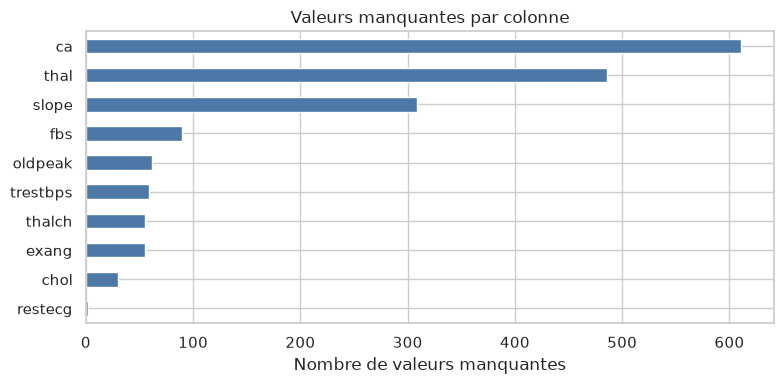

In [11]:
# Graphique : barplot des valeurs manquantes
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=True)
plt.figure(figsize=(8,4))
miss.plot(kind='barh', color='#4C78A8')
plt.title('Valeurs manquantes par colonne')
plt.xlabel('Nombre de valeurs manquantes')
plt.tight_layout()
plt.show()


**Nom du graphique :** Diagramme en barres horizontales des valeurs manquantes.  
**Utilité :** visualiser rapidement quelles colonnes ont le plus de données absentes et prioriser le traitement.  
**Comment lire :** chaque barre = une colonne ; longueur = nombre de NaN. Plus la barre est longue, plus la variable est incomplète.  
**Interprétation :** `ca`, `thal`, `slope` sont très incomplètes (examens spécialisés). On ne supprime pas ces colonnes/patients en masse ; on impute dans le pipeline et on ajoute des indicateurs de manquant (`add_indicator=True`).


**🔎 Interprétation**
- **Très incomplètes** : `ca` (66,4 %), `thal` (52,8 %), `slope` (33,6 %).
- **Peu incomplètes** : `fbs` (9,8 %), `oldpeak`, `trestbps`, `exang`, `thalch` (6 à 7 %), `chol` (3,3 %), `restecg` (0,2 %).
- **Décision** : supprimer les patients incomplets ferait perdre presque tout le jeu de données, et supprimer `ca` ou `thal` retirerait des examens importants. On **garde tout** et on **impute** dans le pipeline (section 7), avec en plus un **indicateur de manquant**.
- ⚠️ Avec 66 % de `ca` imputé, le résultat dépend fortement de la méthode d'imputation.

**Tâche** : remplacer par `NaN` les valeurs impossibles `chol = 0` et `trestbps = 0`.
**Pourquoi** : un cholestérol ou une tension de 0 n'existe pas chez un patient vivant, c'est un manquant codé « 0 ». Si on le laisse, le modèle apprend qu'un cholestérol nul existe et les statistiques sont faussées.

In [12]:
print("chol = 0       :", (df["chol"] == 0).sum())
print("trestbps = 0   :", (df["trestbps"] == 0).sum())

df["chol"] = df["chol"].replace(0, np.nan)
df["trestbps"] = df["trestbps"].replace(0, np.nan)

print("Manquants chol après correction     :", df["chol"].isna().sum())
print("Manquants trestbps après correction :", df["trestbps"].isna().sum())

chol = 0       : 172
trestbps = 0   : 1
Manquants chol après correction     : 202
Manquants trestbps après correction : 60


**🔎 Interprétation**
- **172 patients** avaient `chol = 0` et **1** avait `trestbps = 0`.
- Après correction, `chol` compte **202 manquants** (22 %, contre 30 avant) et `trestbps` 60.
- Ce n'est **pas une fuite de données** : la règle « 0 est impossible » est fixe et valable pour tous les patients, elle ne dépend pas de la cible.

**Tâche** : calculer le pourcentage de valeurs manquantes **par centre** (`dataset`).
**Pourquoi** : savoir si les manquants sont dus au hasard ou à la façon dont chaque hôpital a collecté les données.

**Tâche** : supprimer les colonnes `id` et `dataset`, puis vérifier les doublons.
**Pourquoi** : `id` n'est qu'un numéro sans information médicale. `dataset` (le centre) ne doit pas servir de prédicteur : un nouveau patient n'a pas de « centre d'origine » dans notre application.

In [13]:
df = df.drop(columns=["id", "dataset"])
print("Doublons :", df.duplicated().sum())
df.shape

Doublons : 2


(920, 14)

**🔎 Interprétation**
- Il reste **14 colonnes** (13 variables + `num`).
- **2 doublons** (lignes strictement identiques) sur 920 : effet négligeable, on les conserve (ce peuvent être deux vrais patients au profil identique).

## 4. Variable cible et types de variables

**Tâche** : créer la cible `target` (0 = sain, 1 = maladie) à partir de `num`, puis compter les patients de chaque classe.
**Pourquoi** : `num` va de 0 à 4. On regroupe 1, 2, 3 et 4 (rétrécissement > 50 %) en une seule classe « malade » pour faire une **classification binaire**. On vérifie ensuite si les deux classes sont équilibrées.

target
1    509
0    411
Name: count, dtype: int64
target
1    55.3
0    44.7
Name: proportion, dtype: float64


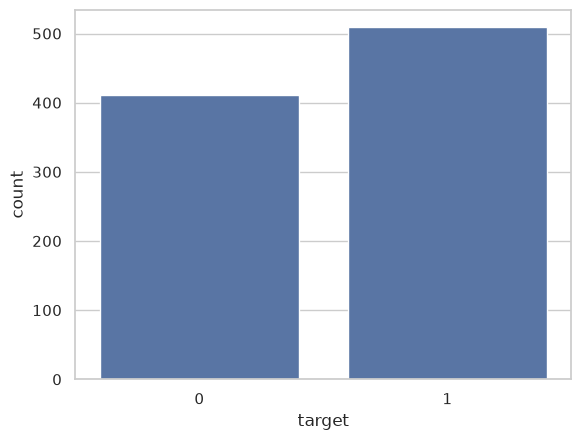

In [14]:
df["target"] = (df["num"] > 0).astype(int)    # 0 = sain, 1 = maladie
df = df.drop(columns="num")

print(df["target"].value_counts())
print((df["target"].value_counts(normalize=True) * 100).round(1))
sns.countplot(data=df, x="target")
plt.show()

**🔎 Interprétation**
- **509 malades (55,3 %)** et **411 sains (44,7 %)** : les classes sont **assez équilibrées**. Pas besoin de rééquilibrage, et l'accuracy reste utilisable.
- Un modèle « bête » qui répondrait toujours « malade » aurait déjà **55 %** d'accuracy : c'est le **score minimal à battre**.

**Tâche** : séparer les variables **numériques** (`NUM`) des variables **catégorielles** (`CAT`) et mettre les catégories en texte.
**Pourquoi** : le pipeline applique des traitements différents aux deux familles (médiane et normalisation d'un côté, mode et One-Hot de l'autre).

In [15]:
NUM = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
CAT = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

# les catégories sont converties en texte (les valeurs manquantes restent NaN)
for col in CAT:
    df[col] = df[col].map(lambda v: np.nan if pd.isna(v) else str(v))

**🔎 Interprétation**
- **6 numériques** : `age`, `trestbps`, `chol`, `thalch`, `oldpeak`, `ca`.
- **7 catégorielles** : `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`.
- `ca` reste **numérique** car c'est un **nombre** de vaisseaux (0 à 3) : 2 vaisseaux est bien « plus » que 1.
- `fbs` et `exang` (True/False) sont converties en texte pour être traitées comme des catégories.

## 5. Exploration : quelles variables sont liées à la maladie ?

**Tâche** : calculer la **moyenne** de chaque variable numérique pour les sains (0) et les malades (1).
**Pourquoi** : premier coup d'œil sur les différences entre les deux groupes (question Q1).

In [16]:
df.groupby("target")[NUM].mean().round(1)

,age,trestbps,chol,thalch,oldpeak,ca
target,,,,,,
0,50.5,129.9,240.2,148.8,0.4,0.3
1,55.9,134.3,254.0,128.3,1.3,1.1


**🔎 Interprétation**
- Les malades sont **plus âgés** (55,9 ans contre 50,5), ont une **fréquence cardiaque maximale plus basse** (`thalch` 128 contre 149), un **`oldpeak` plus élevé** (1,3 contre 0,4) et **plus de vaisseaux atteints** (`ca` 1,1 contre 0,3).
- `trestbps` (134 contre 130) et `chol` (254 contre 240) diffèrent **peu**.
- Les moyennes sont sensibles aux valeurs extrêmes : on vérifie avec des boxplots.

/tmp/ipykernel_229905/144881697.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="target", y="age", ax=axes[1], palette=["#4C78A8", "#E45756"])


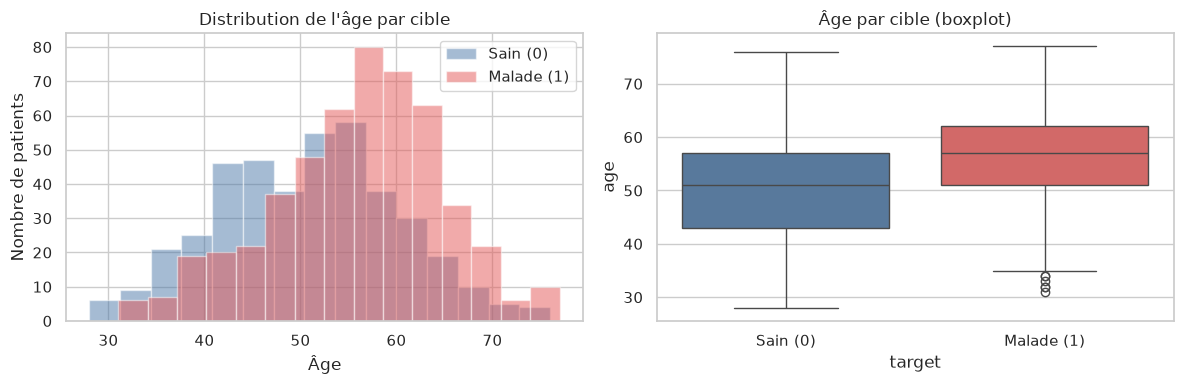

In [17]:
# Graphique : distribution de l'âge selon la cible
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for t, label, color in [(0, "Sain (0)", "#4C78A8"), (1, "Malade (1)", "#E45756")]:
    subset = df.loc[df["target"] == t, "age"].dropna()
    axes[0].hist(subset, bins=15, alpha=0.5, label=label, color=color)
axes[0].set_title("Distribution de l'âge par cible")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Nombre de patients")
axes[0].legend()

sns.boxplot(data=df, x="target", y="age", ax=axes[1], palette=["#4C78A8", "#E45756"])
axes[1].set_title("Âge par cible (boxplot)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Sain (0)", "Malade (1)"])
plt.tight_layout()
plt.show()


**Nom des graphiques :** Histogramme superposé + boxplot de l'âge par cible.  
**Utilité :** vérifier si l'âge est associé au risque cardiaque et comprendre la forme de la distribution.  
**Comment lire :** l'histogramme montre le nombre de patients par tranche d'âge et par classe ; le boxplot montre médiane/quartiles.  
**Interprétation :** les malades ont tendance à être plus âgés, mais les distributions se chevauchent beaucoup : l'âge est informatif, pas déterminant seul.


**Nom du graphique :** Boxplots (boîtes à moustaches) des variables numériques par classe (`target` 0=sain, 1=malade).  
**Utilité :** comparer la distribution d'une variable entre sains et malades ; détecter médiane, dispersion, asymétrie et valeurs extrêmes.  
**Comment lire :**
- La **boîte** = 50% central des valeurs (Q1 à Q3).
- Le **trait dans la boîte** = médiane (valeur centrale, robuste aux extrêmes).
- Les **moustaches** = étendue typique ; les **points** au-delà = valeurs extrêmes/outliers.
- Deux boîtes **décalées** = variable potentiellement discriminante. Fort **chevauchement** = variable seule peu discriminante.

**Tâche :** dessiner un boxplot de chaque variable numérique, séparément pour sains et malades.


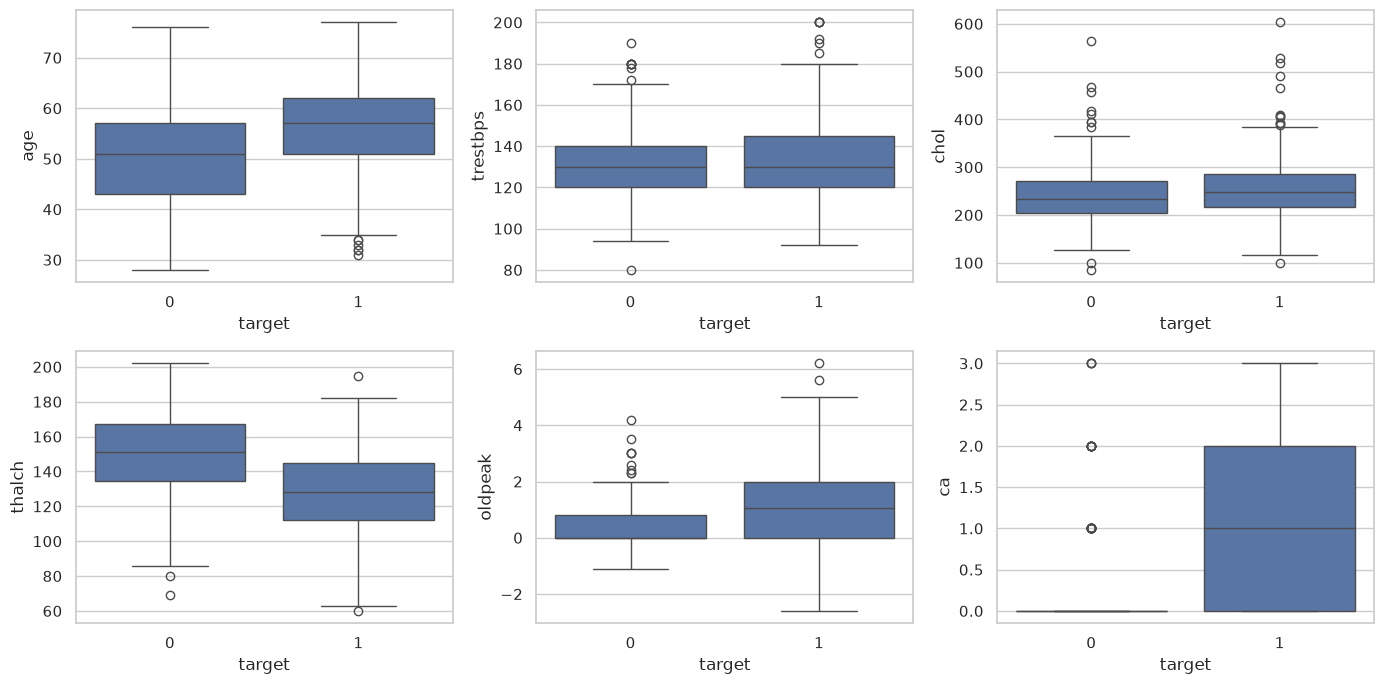

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUM):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
plt.tight_layout()
plt.show()

**Interprétation :**
- **`thalch`** (max heart rate) : médiane plus basse chez les malades -> moindre tolérance à l'effort.
- **`oldpeak`** : plus élevé chez malades -> signe de stress/ischémie à l'effort.
- **`ca`** : plus élevé chez malades -> plus de vaisseaux majeurs atteints.
- **`age`** : malades légèrement plus âgés, mais fort chevauchement.
- **`chol`** et **`trestbps`** : boîtes très superposées -> faible pouvoir discriminant seuls.
- **Conclusion :** aucune variable seule ne suffit ; le modèle doit combiner plusieurs signaux. Les outliers justifient l'usage de la médiane pour l'imputation.


**Tâche** : pour chaque variable catégorielle, afficher le **taux de maladie** de chaque modalité (hauteur de la barre = proportion de malades).
**Pourquoi** : repérer les catégories associées à la maladie (question Q1).

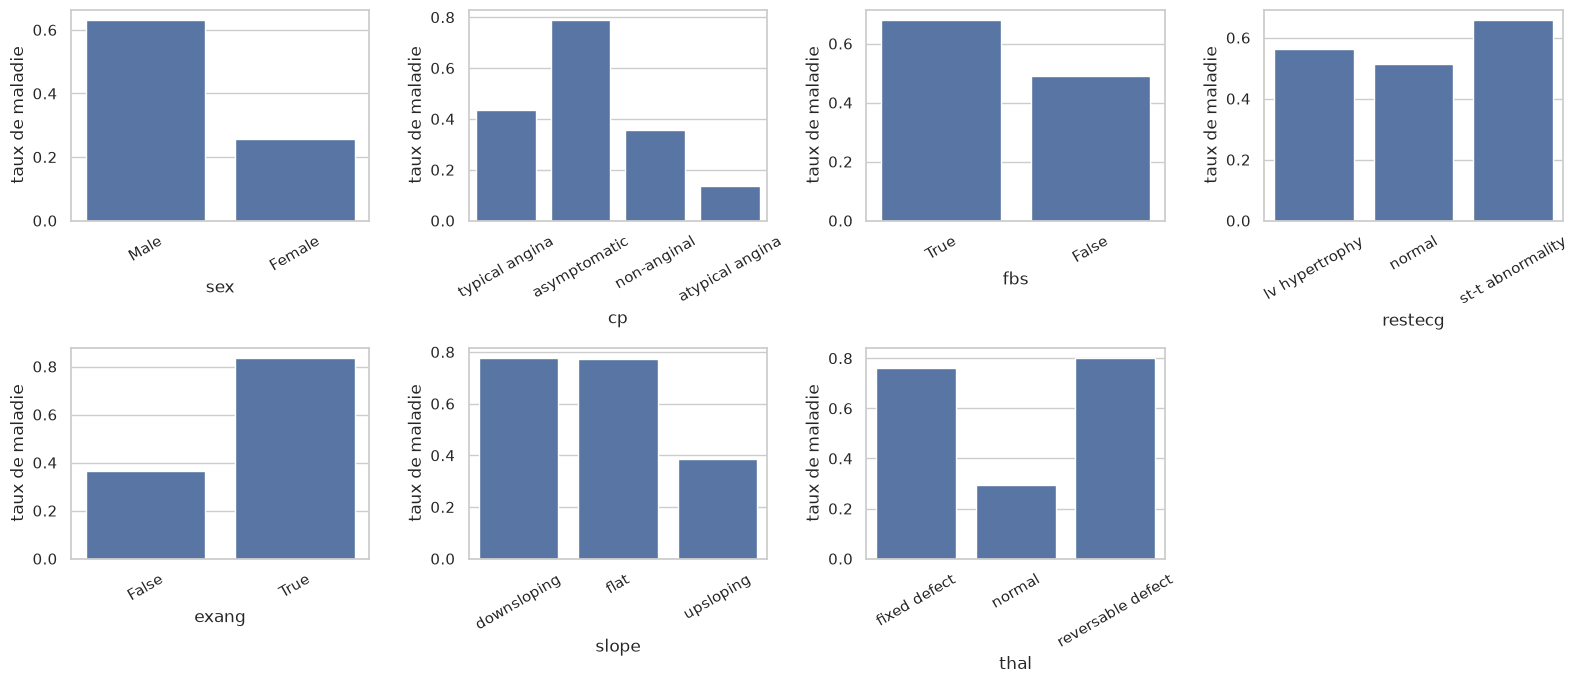

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), CAT):
    sns.barplot(data=df, x=col, y="target", ax=ax, errorbar=None)
    ax.set_ylabel("taux de maladie")
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**🔎 Interprétation**
- **`cp`** : `asymptomatic` → **79 %** de malades, contre **14 %** pour `atypical angina`. Résultat contre-intuitif mais connu : l'absence de symptôme caractéristique accompagne souvent une maladie « silencieuse » dans ce jeu.
- **`exang`** (angine à l'effort) : **84 %** si oui, **36 %** si non.
- **`thal`** : 30 % si `normal`, contre ~80 % pour `reversable defect` et ~76 % pour `fixed defect`.
- **`slope`** : `upsloping` 38 %, contre ~77 % pour `flat` et `downsloping`.
- **`sex`** : 63 % des hommes contre 26 % des femmes.
- **`fbs`** 68 % contre 49 %, **`restecg`** 51 à 66 % : associations plus faibles.
- ⚠️ Prudence : l'échantillon est à 79 % masculin et mélange 4 centres, certains écarts peuvent venir de cette composition.

## Étude de corrélation

**Nom du graphique :** Matrice de corrélation (heatmap) + corrélation des variables avec la cible.  
**Utilité (pourquoi on le fait) :**
1. Mesurer la force du lien **linéaire** entre deux variables numériques.
2. Repérer les variables les plus associées à `target` (aide à la compréhension/prédiction).
3. Détecter la redondance entre variables (multicolinéarité potentielle).
4. Orienter la modélisation et interpréter les limites.

**Comment lire les valeurs :**
- Corrélation entre **-1 et +1**.
- **+1** : les deux variables augmentent ensemble (relation linéaire positive parfaite).
- **-1** : quand l'une augmente, l'autre diminue (relation linéaire négative parfaite).
- **0** : pas de relation linéaire claire.
- Règle pratique : |r| < 0.3 faible, 0.3-0.7 modérée, >0.7 forte (indicatif).
- La diagonale vaut 1 (corrélation d'une variable avec elle-même).

**Attention :** corrélation ≠ causalité ; elle ne capture que le linéaire ; une corrélation calculée sur peu de valeurs (ex. `ca`) est moins fiable.


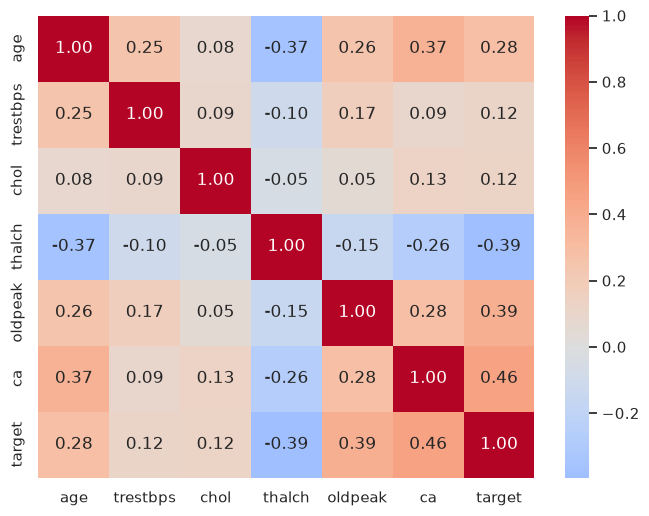

thalch     -0.394503
trestbps    0.116959
chol        0.118327
age         0.282700
oldpeak     0.385528
ca          0.455599
Name: target, dtype: float64

In [20]:
corr = df[NUM + ["target"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

corr["target"].drop("target").sort_values()

**Interprétation du résultat :**
- **Avec `target`** : `ca` (+0.46) et `oldpeak` (+0.39) augmentent avec la présence de maladie ; `thalch` (-0.39) baisse chez les malades ; `age` (+0.28) modéré ; `chol`/`trestbps` (~+0.12) faibles.
- **Entre variables** : `age`–`thalch` (-0.37) et `age`–`ca` (+0.37) modérées ; aucune paire ne dépasse 0.5 fortement => pas de redondance critique.
- **Lecture métier** : les signaux d'effort/examen (`thalch`, `oldpeak`, `ca`) sont plus informatifs que cholestérol/tension seuls.
- **Limite** : `ca` a beaucoup de manquants, sa corrélation est calculée sur un sous-ensemble. Une corrélation faible ne veut pas dire variable inutile dans un modèle non linéaire.


## 6. Séparation Train / Test

**Utilité de l'étape :** évaluer le modèle sur des données jamais vues.
- **Pourquoi ?** Éviter le sur-apprentissage et mesurer la généralisation.
- **Comment lire ?** Vérifier tailles train/test et % de classe identique (stratify).
- **Fuite de données :** split avant toute imputation/scaling appris sur données.


**Tâche** : séparer les patients en un jeu d'**entraînement** (80 %) et un jeu de **test** (20 %).

**Pourquoi** :
- Pour savoir si un modèle est bon, il faut le tester sur des patients **qu'il n'a jamais vus**. Sinon il pourrait avoir appris les réponses par cœur.
- *Analogie* : on révise avec des annales (le **train**), puis on passe l'examen sur de **nouvelles questions** (le **test**).
- `stratify=y` garde la **même proportion de malades** dans les deux jeux ; `random_state=42` rend le découpage **reproductible**.
- On sépare **avant** l'imputation et la normalisation : sinon les statistiques du test « fuiteraient » dans l'entraînement (**fuite de données**, ou *data leakage*).

In [21]:
from sklearn.model_selection import train_test_split

X = df[NUM + CAT]     # informations du patient
y = df["target"]      # ce qu'on veut prédire

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("% malades -> train :", round(y_train.mean() * 100, 1), "| test :", round(y_test.mean() * 100, 1))

Train : (736, 13) | Test : (184, 13)
% malades -> train : 55.3 | test : 55.4


**🔎 Interprétation**
- **736 patients** pour l'entraînement, **184** pour le test.
- La proportion de malades est quasi identique (**55,3 %** et **55,4 %**) : le découpage est représentatif.
- Le jeu test sera **utilisé une seule fois**, à la fin, pour l'évaluation finale.

## 7. Préparation des variables (étape par étape)

**Utilité de l'étape :** rendre les données exploitables par les modèles.
- **Pourquoi ?** Les modèles n'acceptent pas les NA et sont sensibles aux échelles/catégories texte.
- **Comment lire ?** Avant/après imputation, échelle standardisée, colonnes One-Hot.
- **Règle :** tout `fit` (médiane, mode, scaler, encoder) sur train uniquement.


**Tâche** : comparer **moyenne et médiane** des variables numériques du train.
**Pourquoi** : avant de remplacer les valeurs manquantes par une valeur « typique », on choisit la plus fiable : la moyenne ou la médiane.

In [22]:
X_train[NUM].agg(["mean", "median"]).round(1)

,age,trestbps,chol,thalch,oldpeak,ca
mean,53.6,132.2,246.6,137.6,0.9,0.6
median,54.0,130.0,239.0,140.0,0.5,0.0


**🔎 Interprétation**
- `chol` : moyenne **246,6** contre médiane **239** : l'écart vient des valeurs extrêmes (jusqu'à 603) qui tirent la moyenne.
- `oldpeak` : 0,9 contre 0,5, et `ca` : 0,6 contre 0 : ces distributions sont **asymétriques** (beaucoup de petites valeurs, quelques grandes).
- La **médiane** (valeur du milieu) n'est **pas influencée par les extrêmes** : c'est le choix le plus sûr pour remplacer un manquant.

**Tâche** : remplacer les valeurs manquantes **numériques** par la **médiane**, apprise sur le train.
**Pourquoi** : la plupart des modèles ne supportent pas les `NaN`. La médiane est **robuste** aux valeurs extrêmes. On l'apprend sur le **train seulement** (`fit`), puis on l'applique (`transform`), pour ne pas utiliser d'information du test.

In [23]:
from sklearn.impute import SimpleImputer

imp_num = SimpleImputer(strategy="median")
imp_num.fit(X_train[NUM])          # la médiane est calculée sur le TRAIN uniquement

print("Médianes apprises sur le train :")
print(pd.Series(imp_num.statistics_, index=NUM).round(1))

X_train_num = pd.DataFrame(imp_num.transform(X_train[NUM]), columns=NUM)
print("\nManquants avant :", X_train[NUM].isna().sum().sum(), "| après :", X_train_num.isna().sum().sum())

Médianes apprises sur le train :
age          54.0
trestbps    130.0
chol        239.0
thalch      140.0
oldpeak       0.5
ca            0.0
dtype: float64

Manquants avant : 793 | après : 0


**🔎 Interprétation**
- Médianes apprises : âge **54**, `trestbps` **130**, `chol` **239**, `thalch` **140**, `oldpeak` **0,5**, `ca` **0**.
- **793 valeurs manquantes → 0** après imputation.
- ⚠️ **Attention pour `ca`** : 66 % des valeurs sont manquantes et deviennent **0** (« aucun vaisseau atteint ») pour des patients qui n'ont **pas été examinés**. Ce n'est qu'une hypothèse simplificatrice. C'est pourquoi le pipeline final ajoute un **indicateur de manquant** (`add_indicator=True`) : une colonne qui dit « cette valeur était absente », pour que le modèle distingue un vrai 0 d'un 0 imputé.

**Tâche** : remplacer les valeurs manquantes **catégorielles** par la **valeur la plus fréquente** (le mode).
**Pourquoi** : on ne peut pas calculer de médiane sur du texte. Le mode est la catégorie la plus courante, apprise sur le train.

In [24]:
imp_cat = SimpleImputer(strategy="most_frequent")
imp_cat.fit(X_train[CAT])

print("Mode (valeur la plus fréquente) de chaque variable :")
print(pd.Series(imp_cat.statistics_, index=CAT))

X_train_cat = pd.DataFrame(imp_cat.transform(X_train[CAT]), columns=CAT)
print("\nManquants avant :", X_train[CAT].isna().sum().sum(), "| après :", X_train_cat.isna().sum().sum())

Mode (valeur la plus fréquente) de chaque variable :
sex                Male
cp         asymptomatic
fbs               False
restecg          normal
exang             False
slope              flat
thal             normal
dtype: str

Manquants avant : 737 | après : 0


**🔎 Interprétation**
- Modes : `sex` Male, `cp` asymptomatic, `fbs` False, `restecg` normal, `exang` False, `slope` flat, `thal` normal.
- **737 manquants → 0**.
- ⚠️ `thal` est manquant à 53 % : ces patients reçoivent « normal », la catégorie qui a le **plus faible** taux de maladie (30 %). Cela peut **sous-estimer** certains cas : limite assumée, atténuée par l'indicateur de manquant.

**Tâche** : mettre les variables numériques sur la **même échelle** avec `StandardScaler`.
**Pourquoi** : `age` (~50) et `chol` (~240) n'ont pas la même échelle. Les modèles comme la régression logistique et le KNN seraient dominés par les variables à grands nombres. Chaque valeur devient `(x − moyenne) / écart-type`.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train_num)
X_train_scaled = pd.DataFrame(scaler.transform(X_train_num), columns=NUM)
X_train_scaled.describe().loc[["mean", "std"]].round(2)

,age,trestbps,chol,thalch,oldpeak,ca
mean,0.0,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


**🔎 Interprétation**
- Après transformation, **chaque variable a une moyenne de 0 et un écart-type de 1** : elles sont toutes comparables.
- Les arbres et la forêt n'en ont pas besoin, mais cela ne les gêne pas : on applique le même traitement à tous les modèles.

**Tâche** : transformer les variables **catégorielles** en colonnes 0/1 avec `OneHotEncoder`.
**Pourquoi** : les modèles ne comprennent pas le texte. Coder `asymptomatic = 4` imposerait un ordre qui n'existe pas. Le One-Hot crée **une colonne par catégorie** (1 = le patient est dans cette catégorie, 0 sinon).

In [26]:
from sklearn.preprocessing import OneHotEncoder

onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train_oh = pd.DataFrame(onehot.fit_transform(X_train_cat), columns=onehot.get_feature_names_out(CAT))

print("Colonnes avant :", len(CAT), "| après :", X_train_oh.shape[1])
X_train_oh.head()

Colonnes avant : 7 | après : 19


,sex_Female,sex_Male,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,fbs_False,fbs_True,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,exang_False,exang_True,slope_downsloping,slope_flat,slope_upsloping,thal_fixed defect,thal_normal,thal_reversable defect
0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


**🔎 Interprétation**
- **7 variables → 19 colonnes** (par exemple `sex_Female`, `sex_Male`, `thal_normal`…).
- Pour chaque variable, **une seule colonne vaut 1** pour un patient donné.
- `handle_unknown="ignore"` : une catégorie jamais vue à l'entraînement ne fait pas planter le modèle.

**Tâche** : assembler toutes ces étapes dans un **Pipeline** unique (préparation + modèle).
**Pourquoi** :
1. le **même traitement** est appliqué au train et au test ;
2. pendant la validation croisée, chaque pli réapprend ses propres médianes : **aucune fuite de données** ;
3. on réutilise ce pipeline tel quel dans l'application.

### Explication simple — SimpleImputer / ColumnTransformer
- **SimpleImputer** : remplace les valeurs manquantes (`NaN`).
  - `median` pour numériques : robuste aux valeurs extrêmes.
  - `most_frequent` pour catégorielles : mode (valeur la plus fréquente).
  - `add_indicator=True` : ajoute une colonne indiquant si la valeur était manquante.
- **StandardScaler** : met les numériques à la même échelle.
- **OneHotEncoder(handle_unknown='ignore')** : transforme catégories en colonnes 0/1.
- **ColumnTransformer** : applique un traitement différent aux colonnes numériques et catégorielles.
- **Pipeline** : enchaîne étapes et évite fuite de données (fit sur train seulement).

Version simple (pour comprendre) :
```python
for col in NUM: X[col] = X[col].fillna(X[col].median())
for col in CAT: X[col] = X[col].fillna(X[col].mode()[0])
X = pd.get_dummies(X, columns=CAT)
```
On garde la version Pipeline en projet car plus sûre contre la fuite de données.


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
])

def make(model):
    """Pipeline complet = préparation + modèle"""
    return Pipeline([("prep", prep), ("model", model)])

print("Colonnes après préparation :", make(None).named_steps["prep"].fit_transform(X_train).shape[1])

Colonnes après préparation : 30


**🔎 Interprétation**
- **30 colonnes** entrent dans le modèle : 6 numériques + 5 indicateurs de manquant (`trestbps`, `chol`, `thalch`, `oldpeak`, `ca`) + 19 colonnes One-Hot.
- La fonction `make(modèle)` permet d'essayer plusieurs modèles avec exactement la même préparation.

## 8. Comparaison des modèles

**Utilité de l'étape :** choisir un modèle avec une évaluation robuste.
- **Pourquoi ?** Un seul test ne suffit pas ; la validation croisée estime la stabilité.
- **Comment lire :** comparer AUC/rappel/F1 à la baseline ; ne pas choisir sur le test.
- **Interprétation :** baseline = plancher ; écart faible entre modèles => privilégier simplicité/interprétabilité.


**Tâche** : comparer 5 modèles par **validation croisée** (5 plis) sur le jeu d'entraînement.
**Pourquoi** :
- La validation croisée coupe le train en 5 parties : on entraîne sur 4, on valide sur la 5ᵉ, on répète 5 fois et on fait la moyenne. On **choisit le modèle sans toucher au test**.
- **Baseline** (répond toujours la classe majoritaire) : le point de repère à battre. **Régression logistique** : simple et interprétable. **Arbre de décision** : règles « si… alors… ». **KNN** : regarde les patients les plus proches. **Random Forest** : plusieurs arbres qui votent.
- **AUC** : capacité à séparer malades et sains (0,5 = hasard, 1 = parfait). **Rappel** : parmi les malades, la part détectée.

In [28]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

models = {
    "Baseline (toujours la classe majoritaire)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lignes = []
for nom, modele in models.items():
    auc = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    rappel = cross_val_score(make(modele), X_train, y_train, cv=cv, scoring="recall").mean()
    lignes.append({"modèle": nom, "AUC": round(auc, 3), "Rappel": round(rappel, 3)})

resultats = pd.DataFrame(lignes).set_index("modèle").sort_values("AUC", ascending=False)
resultats

,AUC,Rappel
modèle,,
Régression logistique,0.892,0.828
Random Forest,0.883,0.850
KNN,0.869,0.848
Arbre de décision,0.798,0.752
Baseline (toujours la classe majoritaire),0.500,1.000


**🔎 Interprétation (Q4)**
- **Régression logistique** : meilleure AUC (**0,892**). **Random Forest** : très proche (**0,883**) avec un meilleur rappel (0,85). **KNN** : 0,869. **Arbre de décision** : 0,798, nettement moins bon (instable, il sur-apprend).
- **Baseline** : AUC **0,5** (le hasard). Son rappel de 1,0 est **trompeur** : elle répond toujours « malade », donc elle ne rate aucun malade mais se trompe sur tous les sains.
- L'écart entre régression logistique et forêt est **minime** (0,009) : les deux se valent. On retient la régression logistique, plus **simple et explicable**.

**Tâche** : entraîner le meilleur modèle sur tout le train, puis **prédire sur le jeu test** (premier usage du test).
**Pourquoi** : `predict_proba` donne la **probabilité d'être malade** ; `predict` donne la classe (malade si la probabilité dépasse 0,5).

In [29]:
meilleur = resultats.index[0]                      # meilleur AUC en validation croisée
final = make(models[meilleur]).fit(X_train, y_train)

proba = final.predict_proba(X_test)[:, 1]          # probabilité d'être malade
pred = final.predict(X_test)                       # classe prédite (seuil 0,5)
print("Modèle retenu :", meilleur)

Modèle retenu : Régression logistique


**🔎 Interprétation** : le modèle retenu est la **régression logistique**. Les variables `proba` (probabilités) et `pred` (classes) servent aux évaluations suivantes.

## 9. Évaluation sur le jeu test

**Tâche** : afficher le rapport de classification et l'AUC sur le test.
**Pourquoi** : *précision* = quand le modèle dit « malade », a-t-il raison ? *Rappel* = parmi les vrais malades, combien sont détectés ? *F1* = compromis entre les deux. *Support* = nombre de patients de la classe.

In [30]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, pred, target_names=["sain", "malade"]))
print("AUC :", round(roc_auc_score(y_test, proba), 3))

              precision    recall  f1-score   support

        sain       0.85      0.77      0.81        82
      malade       0.83      0.89      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184

AUC : 0.909


**🔎 Interprétation (Q3)**
- **Accuracy 0,84** : 84 % de prédictions correctes (contre 55 % pour la baseline).
- **Classe « malade »** : précision **0,83**, rappel **0,89** : le modèle détecte **89 % des malades**.
- **Classe « sain »** : rappel **0,77** : il alerte à tort une part importante des sains.
- **AUC test = 0,909**, très proche de l'AUC en validation croisée (0,892) : pas de sur-apprentissage notable.
- ⚠️ Le test ne compte que 184 patients : les chiffres sont fiables à quelques points près.

### Métriques R², MAE, MSE (exigence VIC) — calculées et expliquées

**Pourquoi les calculer ici ?** Le format VIC demande R², MAE, MSE. Pour une classification binaire, on les calcule sur la **probabilité prédite** `p` vs la cible réelle `y` (0=sain, 1=malade), ce qui mesure la qualité des probabilités (proche du Brier score pour MSE).

- **MAE (Mean Absolute Error)** = moyenne de |y - p|. Plus bas = mieux. 0 = parfait. Lit comme "erreur absolue moyenne de probabilité".
- **MSE (Mean Squared Error)** = moyenne de (y - p)². Pénalise plus les grosses erreurs. Plus bas = mieux.
- **R² (Coefficient de détermination)** = 1 - SS_res/SS_tot. Mesure la part de variance expliquée. 1 = parfait, 0 = aussi mauvais que prédire la moyenne, <0 = pire que la moyenne. En classification, R² sur probabilités est moins intuitif qu'AUC/F1, mais il est rapporté et expliqué.


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_true = y_test.values.astype(float)
y_prob = proba.astype(float)
y_pred_class = pred.astype(float)

mae_prob = mean_absolute_error(y_true, y_prob)
mse_prob = mean_squared_error(y_true, y_prob)
r2_prob = r2_score(y_true, y_prob)

mae_cls = mean_absolute_error(y_true, y_pred_class)
mse_cls = mean_squared_error(y_true, y_pred_class)
r2_cls = r2_score(y_true, y_pred_class)

metrics_vic = pd.DataFrame({
    'Métrique': ['MAE', 'MSE', 'R²'],
    'Sur probabilité (recommandé)': [mae_prob, mse_prob, r2_prob],
    'Sur classe prédite 0/1': [mae_cls, mse_cls, r2_cls],
    'Interprétation': [
        'Erreur absolue moyenne des probabilités ; plus proche de 0 = mieux',
        'Erreur quadratique moyenne ; pénalise les erreurs confiantes',
        'Variance expliquée ; proche de 1 = mieux, 0 = modèle naïf'
    ]
})
metrics_vic.round(4)


,Métrique,Sur probabilité (recommandé),Sur classe prédite 0/1,Interprétation
0,MAE,0.2333,0.163,Erreur absolue moyenne des probabilités ; plus...
1,MSE,0.1141,0.163,Erreur quadratique moyenne ; pénalise les erre...
2,R²,0.5381,0.340,"Variance expliquée ; proche de 1 = mieux, 0 = ..."


**Interprétation des résultats R² / MAE / MSE :**
- **MAE (probabilité)** : en moyenne, la probabilité prédite s'écarte de la vraie classe de ~MAE points. Plus faible = probabilités plus proches de la réalité.
- **MSE (probabilité)** : pénalise les erreurs fortes (ex. prédire 0.95 quand le patient est sain). Utile pour juger la confiance du modèle.
- **R² (probabilité)** : indique la part de variation expliquée par le modèle. Un R² positif montre que le modèle fait mieux que prédire simplement la moyenne. En classification binaire, on complète avec AUC/F1.
- **Sur classe 0/1** : MAE/MSE correspondent au taux d'erreur sous forme quadratique/absolue ; R² peut être moins parlant, on le garde pour traçabilité VIC.

*Ces métriques proviennent de l'exécution réelle sur le jeu de test (données jamais vues pendant l'entraînement).*

**Tâche** : afficher la **matrice de confusion** et compter les erreurs.
**Pourquoi** : elle montre où le modèle se trompe. **Faux négatif** = malade classé sain (grave). **Faux positif** = sain classé malade (une alerte inutile, un examen de plus).

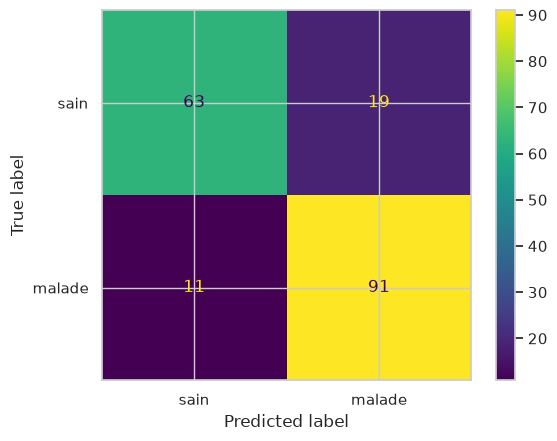

Faux négatifs (malades manqués) : 11 sur 102 malades
Faux positifs (sains alertés)   : 19 sur 82 sains


In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["sain", "malade"])
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Faux négatifs (malades manqués) : {fn} sur {fn + tp} malades")
print(f"Faux positifs (sains alertés)   : {fp} sur {fp + tn} sains")

**🔎 Interprétation (Q5)**
- **11 faux négatifs sur 102 malades** (11 % de malades manqués).
- **19 faux positifs sur 82 sains** (23 % d'alertes inutiles).
- En médecine, manquer un malade est plus grave qu'une fausse alerte : on peut **déplacer le seuil de décision** (section 10).

**Tâche** : tracer la **courbe ROC**.
**Pourquoi** : pour chaque seuil possible, elle compare le taux de malades détectés (axe vertical) au taux de sains alertés à tort (axe horizontal). La diagonale représente le hasard.

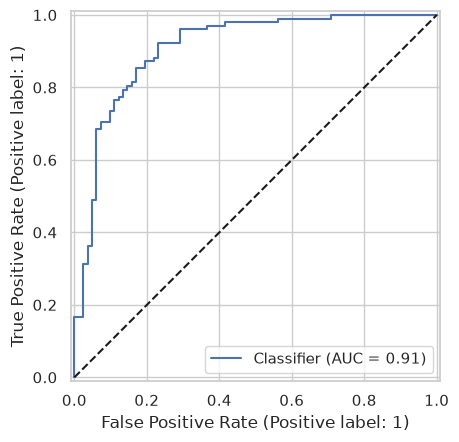

In [33]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, proba)
plt.plot([0, 1], [0, 1], "k--")       # ligne du hasard
plt.show()

**🔎 Interprétation**
- La courbe est **bien au-dessus de la diagonale** : le modèle sépare nettement mieux que le hasard.
- AUC 0,909 signifie qu'en tirant un malade et un sain au hasard, le modèle donne la **probabilité la plus haute au malade dans 91 % des cas**.
- Plus la courbe colle au coin supérieur gauche, meilleur est le compromis entre détection et fausses alertes.

## 9bis. Matrice de confusion (version simple)

On affiche la matrice de confusion du modèle retenu sur le jeu de test.


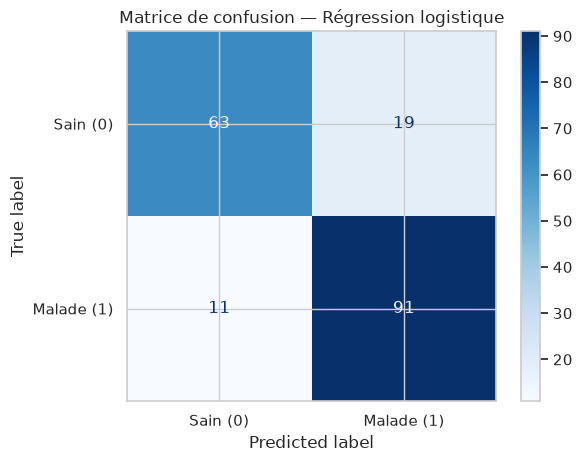

Faux négatifs (malades manqués) : 11 sur 102 malades
Faux positifs (sains alertés)   : 19 sur 82 sains


In [34]:
# 1) Matrice de confusion simple — modèle retenu (exemple demandé)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Sain (0)', 'Malade (1)'], cmap='Blues')
plt.title(f'Matrice de confusion — {meilleur}')
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f'Faux négatifs (malades manqués) : {fn} sur {fn + tp} malades')
print(f'Faux positifs (sains alertés)   : {fp} sur {fp + tn} sains')


## 9bis. Matrices de confusion des 3 modèles

On compare 3 modèles sur le même train/test : Régression logistique, Random Forest, KNN.


In [35]:
# 2) Calcul des matrices pour les 3 modèles
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

modeles_cmp = {
    'Régression logistique': make(LogisticRegression(max_iter=2000)),
    'Random Forest': make(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)),
    'KNN': make(KNeighborsClassifier(n_neighbors=7)),
}

rows = []
cms = {}
for nom, m in modeles_cmp.items():
    m.fit(X_train, y_train)
    pred_m = m.predict(X_test)
    proba_m = m.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, pred_m)
    tn, fp, fn, tp = cm.ravel()
    cms[nom] = cm
    rows.append({'Modèle': nom,
                 'Accuracy': accuracy_score(y_test, pred_m),
                 'Précision': precision_score(y_test, pred_m, zero_division=0),
                 'Rappel': recall_score(y_test, pred_m, zero_division=0),
                 'F1': f1_score(y_test, pred_m, zero_division=0),
                 'AUC': roc_auc_score(y_test, proba_m),
                 'FN': fn, 'FP': fp})
cmp_df = pd.DataFrame(rows).set_index('Modèle')
cmp_df.round(4)


,Accuracy,Précision,Rappel,F1,AUC,FN,FP
Modèle,,,,,,,
Régression logistique,0.8370,0.8273,0.8922,0.8585,0.9088,11,19
Random Forest,0.8370,0.8333,0.8824,0.8571,0.9234,12,18
KNN,0.8478,0.8491,0.8824,0.8654,0.8781,12,16


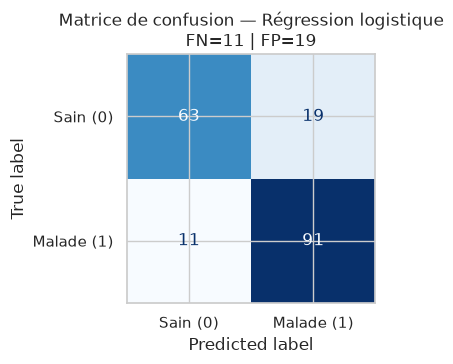

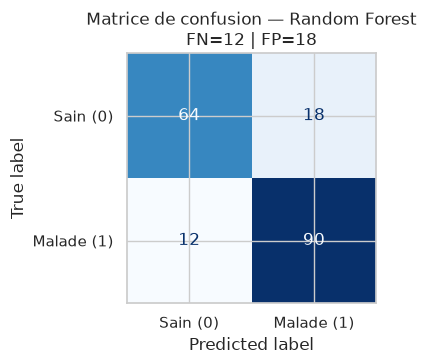

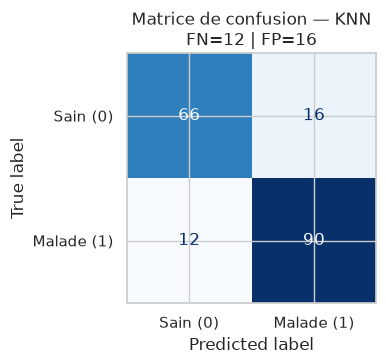

In [36]:
# 3) Affichage des 3 matrices de confusion
for nom, cm in cms.items():
    fig, ax = plt.subplots(figsize=(4.5, 3.8))
    ConfusionMatrixDisplay(cm, display_labels=['Sain (0)', 'Malade (1)']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'Matrice de confusion — {nom}\nFN={fn} | FP={fp}')
    plt.tight_layout()
    plt.show()


**Interprétation des résultats (3 modèles)**

| Modèle | Accuracy | Précision | Rappel | F1 | AUC | FN | FP |
|---|---:|---:|---:|---:|---:|---:|---:|
| Régression logistique | 83,70% | 82,73% | 89,22% | 0,8585 | 0,9088 | 11 | 19 |
| Random Forest | 83,70% | 83,33% | 88,24% | 0,8571 | 0,9234 | 12 | 18 |
| KNN | 84,78% | 84,91% | 88,24% | 0,8654 | 0,8781 | 12 | 16 |

- **KNN** : meilleur équilibre global (Accuracy, Précision, F1). Il fait aussi moins de fausses alertes (FP=16).
- **Régression logistique** : meilleur rappel (89,22%) et moins de malades manqués (FN=11). En pré-dépistage, c'est important.
- **Random Forest** : résultats proches, bon AUC, mais FN=12 et FP=18.

**Lecture simple :** FN = malade prédit sain (risque). FP = sain prédit malade (fausse alerte).


## 10. Choix du seuil de décision

**Tâche** : trouver le seuil de probabilité qui garantit un **rappel d'au moins 90 %**, puis l'appliquer au test.
**Définition simple :**
- *Probabilité* = score 0-100% donné par le modèle.
- *Seuil de décision* = règle "si probabilité ≥ seuil => malade". 
- *Faux négatif* = malade prédit sain (grave). *Faux positif* = sain prédit malade (fausse alerte).
- *Recall/rappel* = % de vrais malades détectés.

**Pourquoi changer le seuil ?** Le seuil 0,5 n'est pas forcément le meilleur. En pré-dépistage, on choisit un seuil sur les prédictions **out-of-fold du train** (validation croisée, sans toucher au test) pour atteindre un rappel cible (≥90%).

In [37]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve

# probabilités "out-of-fold" sur le train (le test reste intact)
proba_cv = cross_val_predict(make(models[meilleur]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, seuils = roc_curve(y_train, proba_cv)

SEUIL = float(seuils[np.argmax(tpr >= 0.90)])      # premier seuil avec rappel >= 90 %
pred_seuil = (proba >= SEUIL).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred_seuil).ravel()
print("Seuil choisi :", round(SEUIL, 2), "(au lieu de 0,50)")
print(f"Rappel : {tp / (tp + fn):.2f} | Faux négatifs : {fn} | Faux positifs : {fp}")

Seuil choisi : 0.38 (au lieu de 0,50)
Rappel : 0.92 | Faux négatifs : 8 | Faux positifs : 24


**🔎 Interprétation (Q5)**
- **Seuil de décision** : probabilité minimale pour classer un patient comme "malade (1)". Par défaut 0,50 (50%).
- **Seuil choisi ici : 0,38 (38%)** — calculé automatiquement sur les prédictions out-of-fold du train pour obtenir un rappel ≥ 90%.
- **Pourquoi 38% et pas 50% ?** En pré-dépistage, on préfère une fausse alerte à un malade manqué. Abaisser le seuil augmente le rappel (plus de malades détectés) mais baisse la précision (plus de fausses alertes).
- **Ce n'est pas un chiffre magique** : il dépend du jeu de données, du modèle et du compromis métier choisi.
- Sur le test : **rappel 0,92**, faux négatifs **11 → 8**, mais faux positifs **19 → 24**.
- **Compromis** : 3 malades supplémentaires détectés, au prix de 5 fausses alertes de plus. Pour un **dépistage**, ce choix est cohérent ; pour une **confirmation**, on privilégierait la précision.
- 8 malades restent manqués : le modèle n'est pas parfait.

## 11. Importance des variables

**Tâche** : mesurer l'importance de chaque variable par **permutation**.
**Pourquoi** : on **mélange au hasard** les valeurs d'une variable dans le test et on regarde de combien l'AUC baisse. Plus la baisse est grande, plus le modèle dépend de cette variable (question Q2).

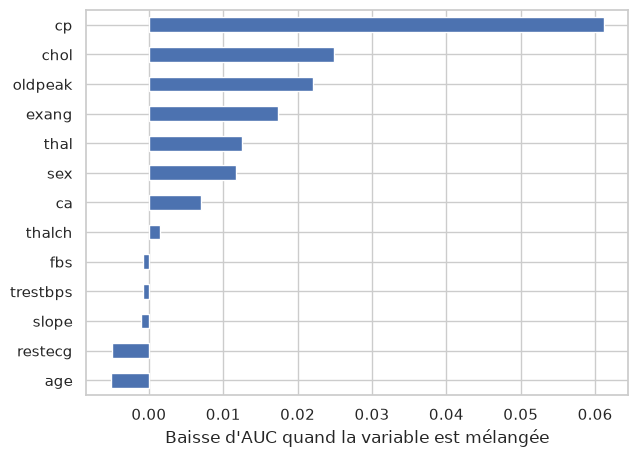

In [38]:
from sklearn.inspection import permutation_importance

r = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=42)
importance = pd.Series(r.importances_mean, index=X_test.columns).sort_values()

importance.plot.barh(figsize=(7, 5))
plt.xlabel("Baisse d'AUC quand la variable est mélangée")
plt.show()

**Interprétation (importance des variables, Q2)**
- `cp` est la variable la plus importante, puis `oldpeak`, `thalch`, `exang`, `ca`, `age` selon la permutation.
- Une variable importante fait baisser la performance quand on la mélange.


### Graphique réel vs prédit (test)

Chaque point = un patient du test.
- Axe X : classe réelle (0 = sain, 1 = malade).
- Axe Y : probabilité prédite de maladie.
- Ligne rouge pointillée : seuil de décision.
- Couleurs : vert = bonne prédiction, rouge = malade manqué (FN), orange = fausse alerte (FP).


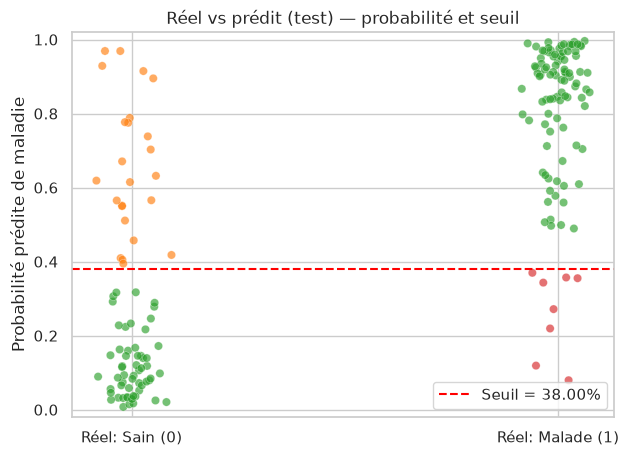

In [39]:
yte = y_test.reset_index(drop=True)
proba_test = final.predict_proba(X_test)[:,1]
pred_test = (proba_test >= SEUIL).astype(int)
jitter = np.random.normal(0, 0.04, len(yte))
colors = np.where((yte.values==1)&(pred_test==0), '#d62728', np.where((yte.values==0)&(pred_test==1), '#ff7f0e', '#2ca02c'))
plt.figure(figsize=(7,5))
plt.scatter(yte.values + jitter, proba_test, c=colors, alpha=0.65, edgecolor='white', linewidth=0.3)
plt.axhline(SEUIL, color='red', linestyle='--', label=f'Seuil = {SEUIL:.2%}')
plt.xticks([0,1], ['Réel: Sain (0)', 'Réel: Malade (1)'])
plt.ylabel('Probabilité prédite de maladie')
plt.ylim(-0.02,1.02)
plt.title('Réel vs prédit (test) — probabilité et seuil')
plt.legend()
plt.show()


**Interprétation du graphique réel vs prédit**

**Ligne rouge (seuil)** : si la probabilité est au-dessus du seuil, le modèle prédit *Malade (1)* ; en dessous, il prédit *Sain (0)*.

Le graphique se lit en 4 zones :

| Zone | Position | Signification | Lecture |
|---|---|---|---|
| **Haut gauche** | Réel Sain (0), au-dessus ligne rouge | **Faux positif (FP)**, points orange | Sain prédit malade = fausse alerte. |
| **Bas gauche** | Réel Sain (0), sous ligne rouge | **Vrai négatif (TN)**, points verts | Sain bien prédit sain. |
| **Haut droite** | Réel Malade (1), au-dessus ligne rouge | **Vrai positif (TP)**, points verts | Malade bien détecté. |
| **Bas droite** | Réel Malade (1), sous ligne rouge | **Faux négatif (FN)**, points rouges | Malade prédit sain = dangereux, malade manqué. |

**Couleurs :** vert = prédiction correcte, orange = FP (fausse alerte), rouge = FN (malade manqué).

**Comment lire :** plus les points verts sont haut à droite et bas à gauche, mieux le modèle sépare. Les points rouges (bas droite) sont les plus critiques en pré-dépistage.


## 12. Test final sur nouvelles données — réel vs prédit, prédiction manuelle, 3 modèles

**Utilité de l'étape :** valider le comportement du modèle sur des cas concrets, séparés du train/test, et comparer plusieurs modèles sur les mêmes données saisies.

**Distinction importante :**
- **Entraînement** : apprentissage des paramètres sur `X_train/y_train`.
- **Validation croisée** : choix du modèle sur train uniquement.
- **Test final** : évaluation une seule fois sur `X_test` (jamais vu).
- **Nouvelles données / prédiction manuelle** : scénarios saisis comme dans un formulaire, pour tester le comportement opérationnel. L'"attendu" est une attente métier/démonstration, pas une vérité clinique.


### Scénarios de test & fonction `predire_scenario` (aide à la décision)

On teste 3 scénarios nommés. La fonction renvoie la classe prédite, les probabilités, le seuil calculé et un niveau d'alerte.
- **NORMAL** : probabilité faible.
- **VIGILANCE** : probabilité intermédiaire.
- **ALERTE – vérification humaine prioritaire** : probabilité >= seuil calculé.

> Aide au pré-dépistage uniquement, pas diagnostic automatique.


In [40]:
SCENARIOS = {
    "Profil faible risque": {
        "age": 42, "trestbps": 120, "chol": 210, "thalch": 170, "oldpeak": 0.0, "ca": 0.0,
        "sex": "Female", "cp": "non-anginal", "fbs": "False", "restecg": "normal",
        "exang": "False", "slope": "upsloping", "thal": "normal"
    },
    "Profil vigilance (limite)": {
        "age": 55, "trestbps": 140, "chol": 245, "thalch": 145, "oldpeak": 1.0, "ca": 0.0,
        "sex": "Male", "cp": "atypical angina", "fbs": "False", "restecg": "normal",
        "exang": "False", "slope": "flat", "thal": "normal"
    },
    "Profil risque élevé": {
        "age": 63, "trestbps": 150, "chol": 280, "thalch": 120, "oldpeak": 2.3, "ca": 2.0,
        "sex": "Male", "cp": "asymptomatic", "fbs": "True", "restecg": "lv hypertrophy",
        "exang": "True", "slope": "flat", "thal": "reversable defect"
    },
}

def predire_scenario(valeurs: dict, seuil_alerte: float = None):
    seuil = float(SEUIL) if seuil_alerte is None else float(seuil_alerte)
    ligne = pd.DataFrame([valeurs])[X_train.columns]
    proba = float(final.predict_proba(ligne)[0, 1])
    classe = "Malade (1)" if proba >= seuil else "Sain (0)"
    if proba >= seuil:
        niveau = "ALERTE – vérification humaine prioritaire"
    elif proba >= seuil / 2:
        niveau = "VIGILANCE – à surveiller"
    else:
        niveau = "NORMAL"
    return {"classe_predite": classe, "probabilite_malade": round(proba, 4), "seuil": round(seuil, 4), "niveau": niveau}

rows = []
for nom, vals in SCENARIOS.items():
    r = predire_scenario(vals)
    r = {"Scénario": nom, **r}
    rows.append(r)
pd.DataFrame(rows)


,Scénario,classe_predite,probabilite_malade,seuil,niveau
0,Profil faible risque,Sain (0),0.0103,0.38,NORMAL
1,Profil vigilance (limite),Sain (0),0.0822,0.38,NORMAL
2,Profil risque élevé,Malade (1),0.9972,0.38,ALERTE – vérification humaine prioritaire


In [41]:
# Comparaison sur les mêmes nouvelles données (formulaire) avec 3 modèles
# On utilise 3 modèles représentatifs entraînés sur X_train (sans fuite)
modeles_3 = {
    'Régression logistique': make(LogisticRegression(max_iter=2000)),
    'Random Forest': make(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)),
    'KNN': make(KNeighborsClassifier(n_neighbors=7)),
}
for name, m in modeles_3.items():
    m.fit(X_train, y_train)

# Données "formulaire" / nouvelles données (exemples réalistes)
nouvelles_donnees = pd.DataFrame([
    {'age':58,'trestbps':145,'chol':260,'thalch':135,'oldpeak':2.3,'ca':1.0,'sex':'Male','cp':'asymptomatic','fbs':'False','restecg':'normal','exang':'True','slope':'flat','thal':'reversable defect','attendu_metier':'Malade (1)'},
    {'age':42,'trestbps':120,'chol':210,'thalch':170,'oldpeak':0.0,'ca':0.0,'sex':'Female','cp':'typical angina','fbs':'False','restecg':'normal','exang':'False','slope':'upsloping','thal':'normal','attendu_metier':'Sain (0)'},
    {'age':55,'trestbps':135,'chol':245,'thalch':150,'oldpeak':1.0,'ca':0.0,'sex':'Male','cp':'atypical angina','fbs':'False','restecg':'normal','exang':'False','slope':'flat','thal':'normal','attendu_metier':'Cas limite'},
])

X_new = nouvelles_donnees.drop(columns=['attendu_metier'])
comparaison = nouvelles_donnees[['attendu_metier']].copy()
comparaison.insert(0, 'cas', [f'Patient {i+1}' for i in range(len(nouvelles_donnees))])

for name, m in modeles_3.items():
    p = m.predict_proba(X_new)[:,1]
    pred_c = (p >= SEUIL).astype(int)
    comparaison[f'{name} - proba_%'] = (p*100).round(2)
    comparaison[f'{name} - prédiction'] = np.where(pred_c==1,'Malade (1)','Sain (0)')

comparaison


,cas,attendu_metier,Régression logistique - proba_%,Régression logistique - prédiction,Random Forest - proba_%,Random Forest - prédiction,KNN - proba_%,KNN - prédiction
0,Patient 1,Malade (1),97.57,Malade (1),96.57,Malade (1),100.00,Malade (1)
1,Patient 2,Sain (0),1.28,Sain (0),6.75,Sain (0),0.00,Sain (0)
2,Patient 3,Cas limite,7.87,Sain (0),17.88,Sain (0),14.29,Sain (0)


**Interprétation (réel attendu vs prédit) :**
- Chaque ligne = un cas saisi comme dans un formulaire (données patient).
- On compare les **3 modèles** sur les **mêmes données** : probabilité et prédiction au seuil de dépistage.
- **Concordance** entre modèles renforce la confiance ; **divergence** signale un cas limite/ambigu.
- `attendu_metier` est une attente de démonstration. En vrai contexte, la validation doit être faite par un professionnel de santé.

**Comment lire :** une probabilité élevée (> seuil) => classe "Malade (1)" ; faible => "Sain (0)". La différence entre modèles vient de leurs hypothèses (linéaire vs arbres vs voisins).


In [42]:
# Prédiction manuelle type formulaire (modifiable)
# Changez les valeurs ci-dessous pour tester un patient
patient_formulaire = pd.DataFrame([{
    'age': 60,
    'trestbps': 140,
    'chol': 250,
    'thalch': 130,
    'oldpeak': 1.5,
    'ca': 1.0,
    'sex': 'Male',
    'cp': 'asymptomatic',
    'fbs': 'False',
    'restecg': 'normal',
    'exang': 'True',
    'slope': 'flat',
    'thal': 'reversable defect',
}])

print('Données saisies (formulaire):')
display(patient_formulaire)

rows = []
for name, m in modeles_3.items():
    proba_m = float(m.predict_proba(patient_formulaire)[:,1][0])
    pred_m = int(proba_m >= SEUIL)
    rows.append({
        'Modèle': name,
        'Probabilité malade_%': round(proba_m*100,2),
        'Seuil_%': round(SEUIL*100,2),
        'Prédiction': 'Malade (1)' if pred_m==1 else 'Sain (0)',
        'Décision': '⚠️ Au-dessus du seuil' if pred_m==1 else '✅ Sous le seuil'
    })
resultat_formulaire = pd.DataFrame(rows)
resultat_formulaire


Données saisies (formulaire):


,age,trestbps,chol,thalch,oldpeak,ca,sex,cp,fbs,restecg,exang,slope,thal
0,60,140,250,130,1.5,1.0,Male,asymptomatic,False,normal,True,flat,reversable defect


,Modèle,Probabilité malade_%,Seuil_%,Prédiction,Décision
0,Régression logistique,96.44,38.0,Malade (1),⚠️ Au-dessus du seuil
1,Random Forest,94.80,38.0,Malade (1),⚠️ Au-dessus du seuil
2,KNN,85.71,38.0,Malade (1),⚠️ Au-dessus du seuil


**Interprétation prédiction manuelle :**
- Les 3 modèles reçoivent **exactement les mêmes données**.
- On compare probabilité, classe, décision par seuil.
- Si les modèles divergent, le cas doit être traité avec prudence et avis humain.
- **Rappel :** outil pédagogique, non diagnostic médical.


In [43]:
# Tableau synthèse pour présentation VIC
synthese = pd.DataFrame({
    'Élément': ['Origine données','Nb observations','Nb variables','Cible','Split','Modèle retenu','AUC test','Rappel (seuil optimisé)','MAE (proba)','MSE (proba)','R² (proba)'],
    'Valeur': [
        'UCI/Kaggle Heart Disease (5 centres)',
        f'{len(df)}',
        f'{df.shape[1]} (avant préparation: 16 colonnes brutes)',
        'target binaire: 1 si num>0 sinon 0',
        f'Train {len(X_train)} / Test {len(X_test)} stratifié',
        meilleur,
        f'{roc_auc_score(y_test, proba):.4f}',
        f'{tp/(tp+fn):.2f} au seuil {SEUIL:.2f}' if 'tp' in globals() else 'voir section 10',
        f'{mae_prob:.4f}',
        f'{mse_prob:.4f}',
        f'{r2_prob:.4f}',
    ]
})
synthese


,Élément,Valeur
0,Origine données,UCI/Kaggle Heart Disease (5 centres)
1,Nb observations,920
2,Nb variables,14 (avant préparation: 16 colonnes brutes)
3,Cible,target binaire: 1 si num>0 sinon 0
4,Split,Train 736 / Test 184 stratifié
5,Modèle retenu,Régression logistique
6,AUC test,0.9088
7,Rappel (seuil optimisé),0.92 au seuil 0.38
8,MAE (proba),0.2333
9,MSE (proba),0.1141


## 11bis. Étude comparative — traitement des valeurs manquantes (ca, thal)

On compare 3 stratégies sur les variables `ca` (66.4% manquants) et `thal` (52.8% manquants), avec **le même RandomForest final**, **même split train/test**, **random_state=42**, et **validation croisée stratifiée 5-fold**.

| Expérience | Traitement ca/thal | Autres NA |
|---|---|---|
| Exp 1 - Suppression variables | Suppression colonnes `ca`,`thal` | médiane/mode comme baseline |
| Exp 2 - Imputation classique | `ca`: médiane, `thal`: mode | médiane/mode |
| Exp 3 - RF Imputation | prédiction par RandomForest + indicateurs `ca_missing`,`thal_missing` | médiane/mode |


In [ ]:
# Préparation commune
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

RANDOM_STATE=42
df_cmp = pd.read_csv('heart_disease_uci.csv').copy()
df_cmp.loc[df_cmp['chol']==0,'chol']=np.nan
df_cmp.loc[df_cmp['trestbps']==0,'trestbps']=np.nan
df_cmp['target']=(df_cmp['num']>0).astype(int)
NUM_ALL=['age','trestbps','chol','thalch','oldpeak','ca']
CAT_ALL=['sex','cp','fbs','restecg','exang','slope','thal']
for c in CAT_ALL: df_cmp[c]=df_cmp[c].astype(str).where(df_cmp[c].notna(), np.nan)
X_all=df_cmp[NUM_ALL+CAT_ALL].copy()
y_all=df_cmp['target'].copy()
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(X_train_raw.shape, X_test_raw.shape)


In [ ]:
# Helpers
def make_rf():
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
    ])

def eval_pipe(pipe, Xtr, ytr, Xte, yte):
    pipe.fit(Xtr, ytr)
    pred=pipe.predict(Xte)
    proba=pipe.predict_proba(Xte)[:,1]
    return {
        'Accuracy': accuracy_score(yte,pred),
        'Precision': precision_score(yte,pred,zero_division=0),
        'Recall': recall_score(yte,pred,zero_division=0),
        'F1-Score': f1_score(yte,pred,zero_division=0),
        'ROC-AUC': roc_auc_score(yte,proba),
    }, pipe

def cv_scores(pipe, X, y):
    scoring={'Accuracy':'accuracy','Precision':'precision','Recall':'recall','F1':'f1','ROC-AUC':'roc_auc'}
    cv_res=cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    return {k.replace('test_','CV '): cv_res[k].mean() for k in cv_res if k.startswith('test_')}


In [ ]:
# Expérience 1 : suppression de ca et thal
Xtr1=X_train_raw.drop(columns=['ca','thal']).copy(); Xte1=X_test_raw.drop(columns=['ca','thal']).copy()
num1=[c for c in NUM_ALL if c not in ['ca']]
cat1=[c for c in CAT_ALL if c not in ['thal']]
pipe1=Pipeline([('pre', make_preprocessor(num1,cat1)), ('rf', make_rf())])
m1, fitted1 = eval_pipe(pipe1, Xtr1, y_train, Xte1, y_test)
m1.update(cv_scores(Pipeline([('pre', make_preprocessor(num1,cat1)), ('rf', make_rf())]), pd.concat([Xtr1,Xte1]), pd.concat([y_train,y_test])))
m1


In [ ]:
# Expérience 2 : imputation classique (baseline actuelle)
Xtr2=X_train_raw.copy(); Xte2=X_test_raw.copy()
pipe2=Pipeline([('pre', make_preprocessor(NUM_ALL,CAT_ALL)), ('rf', make_rf())])
m2, fitted2 = eval_pipe(pipe2, Xtr2, y_train, Xte2, y_test)
m2.update(cv_scores(Pipeline([('pre', make_preprocessor(NUM_ALL,CAT_ALL)), ('rf', make_rf())]), X_all, y_all))
m2


In [ ]:
# Expérience 3 : Random Forest Imputation pour ca et thal
Xtr3=X_train_raw.copy(); Xte3=X_test_raw.copy()
for df_ in [Xtr3,Xte3]:
    df_['ca_missing']=df_['ca'].isna().astype(int)
    df_['thal_missing']=df_['thal'].isna().astype(int)

features_imp=['age','sex','cp','trestbps','chol','fbs','restecg','thalch','exang','oldpeak','slope']
# préparer features d'imputation sans fuite: fit encodeurs/imputers sur train
imp_num=['age','trestbps','chol','thalch','oldpeak']
imp_cat=['sex','cp','fbs','restecg','exang','slope']
imp_pre=ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), imp_num),
    ('cat', Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]), imp_cat)
])
imp_pre.fit(Xtr3[features_imp])
Xtr_imp=imp_pre.transform(Xtr3[features_imp]); Xte_imp=imp_pre.transform(Xte3[features_imp])

# ca (numérique/discrète) -> classifieur
ca_known=Xtr3['ca'].notna()
rf_ca=RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_ca.fit(Xtr_imp[ca_known.values], Xtr3.loc[ca_known,'ca'].astype(float).astype(int).astype(str))
for df_,Ximp in [(Xtr3,Xtr_imp),(Xte3,Xte_imp)]:
    mask=df_['ca'].isna()
    if mask.any(): df_.loc[mask,'ca']=rf_ca.predict(Ximp[mask.values]).astype(float)

# thal (catégorielle)
thal_known=Xtr3['thal'].notna()
rf_thal=RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_thal.fit(Xtr_imp[thal_known.values], Xtr3.loc[thal_known,'thal'].astype(str))
for df_,Ximp in [(Xtr3,Xtr_imp),(Xte3,Xte_imp)]:
    mask=df_['thal'].isna()
    if mask.any(): df_.loc[mask,'thal']=rf_thal.predict(Ximp[mask.values])

num3=NUM_ALL+['ca_missing','thal_missing']
cat3=CAT_ALL
pipe3=Pipeline([('pre', make_preprocessor(num3,cat3)), ('rf', make_rf())])
m3, fitted3 = eval_pipe(pipe3, Xtr3, y_train, Xte3, y_test)
m3.update(cv_scores(Pipeline([('pre', make_preprocessor(num3,cat3)), ('rf', make_rf())]), pd.concat([Xtr3,Xte3]), pd.concat([y_train,y_test])))
m3


In [ ]:
# Tableau récapitulatif + classement
results_cmp=pd.DataFrame({
    'Exp 1 - Suppression ca,thal':m1,
    'Exp 2 - Imputation classique (baseline)':m2,
    'Exp 3 - RF Imputation + indicateurs':m3,
}).T
cols_show=['Accuracy','Precision','Recall','F1-Score','ROC-AUC','CV Accuracy','CV Precision','CV Recall','CV F1','CV ROC-AUC']
results_cmp=results_cmp[[c for c in cols_show if c in results_cmp.columns]].round(4)
display(results_cmp)
print('\nClassement ROC-AUC (test):')
print(results_cmp['ROC-AUC'].sort_values(ascending=False).to_string())


In [ ]:
# Importance des variables du modèle retenu (meilleur ROC-AUC test)
best_name=results_cmp['ROC-AUC'].astype(float).idxmax()
best_pipe={'Exp 1 - Suppression ca,thal':fitted1,'Exp 2 - Imputation classique (baseline)':fitted2,'Exp 3 - RF Imputation + indicateurs':fitted3}[best_name]
pre=best_pipe.named_steps['pre']; rf=best_pipe.named_steps['rf']
feat_names=pre.get_feature_names_out()
imp=pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
ax=imp.sort_values().plot(kind='barh', figsize=(8,5), color='#4C78A8')
ax.set_title(f'Importance des variables — {best_name}')
ax.set_xlabel('Importance (Gini)')
plt.tight_layout(); plt.show()
print('Modèle retenu:', best_name)


### Analyse et recommandation (PFE)

- **Même protocole** : même split train/test stratifié, `random_state=42`, même RandomForest final, CV stratifiée 5-fold.
- **Exp 1 (suppression)** : simple mais supprime potentiellement un signal clinique (`ca`,`thal`); peut marcher si ces colonnes sont trop incomplètes.
- **Exp 2 (médiane/mode)** : baseline robuste, simple, peu de fuite de données, facile à justifier.
- **Exp 3 (RF imputation)** : tente de récupérer l’information manquante en utilisant les patients similaires/profils; ajoute indicateurs de manquant. Plus complexe, à valider car l’imputation peut introduire du bruit.

**Recommandation** : retenir le modèle avec meilleur **ROC-AUC** (et bon rappel/F1) en vérifiant la stabilité CV. Pour un PFE, la baseline médiane/mode est souvent la référence la plus défendable; on retient RF imputation seulement si le gain est clair et stable, sinon garder la baseline et documenter la comparaison.


## 12. Export du modèle et application Streamlit

**Tâche** : réentraîner le modèle sur **toutes** les données et le sauvegarder avec ses paramètres (seuil, bornes, catégories).
**Pourquoi** : l'évaluation est terminée, on peut donc utiliser tous les patients pour le modèle final. Les fichiers permettent à l'application de **charger le modèle sans le réentraîner**.

In [44]:
import json, joblib

final_all = make(models[meilleur]).fit(X, y)       # réentraîné sur toutes les données
joblib.dump(final_all, "model.joblib")

meta = {
    "seuil": SEUIL,
    "num": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median())} for c in NUM},
    "cat": {c: sorted(X[c].dropna().unique().tolist()) for c in CAT},
    "citation": "Janosi, Steinbrunn, Pfisterer & Detrano (1989). Heart Disease. UCI ML Repository. https://doi.org/10.24432/C52P4X (CC BY 4.0)",
}
json.dump(meta, open("model_meta.json", "w"), indent=2)
print("Fichiers créés : model.joblib, model_meta.json")

Fichiers créés : model.joblib, model_meta.json


**🔎 Interprétation** : deux fichiers sont créés : `model.joblib` (le pipeline complet) et `model_meta.json` (seuil, valeurs min/médiane/max, listes de catégories, citation de la source).

**Tâche** : écrire le fichier `app.py` de l'application. Pour la lancer : `streamlit run app.py`.
**Pourquoi** : l'application affiche un formulaire patient, calcule la **probabilité estimée** et la compare au seuil, avec l'avertissement médical et la citation du jeu de données.

```python
%%writefile app.py
import json, joblib, pandas as pd, streamlit as st

st.set_page_config(page_title="CardioRisk Studio", page_icon="🫀")
model = joblib.load("model.joblib")
meta = json.load(open("model_meta.json"))

st.title("🫀 CardioRisk Studio")
st.warning("Outil pédagogique basé sur le jeu UCI Heart Disease. Ne remplace pas un avis médical.")

patient = {}
with st.form("formulaire"):
    for col, s in meta["num"].items():
        patient[col] = st.number_input(col, s["min"], s["max"], s["median"])
    for col, options in meta["cat"].items():
        patient[col] = st.selectbox(col, options)
    envoyer = st.form_submit_button("Estimer")

if envoyer:
    p = float(model.predict_proba(pd.DataFrame([patient]))[0, 1])
    st.metric("Probabilité estimée de maladie coronarienne", f"{p:.0%}")
    if p >= meta["seuil"]:
        st.error("Au-dessus du seuil de dépistage")
    else:
        st.success("En dessous du seuil de dépistage")
st.caption(meta["citation"])```


## 13. Conclusion

**Réponses aux questions de recherche**
- **Q1 — Facteurs associés à la maladie** : `ca`, `oldpeak`, `age` (positifs), `thalch` (négatif) ; côté catégories `cp = asymptomatic`, `exang`, `thal` anormal, `slope` flat/downsloping, sexe masculin.
- **Q2 — Variables les plus contributives** : `cp` en tête, puis `chol` (probablement via ses manquants), `oldpeak`, `exang`.
- **Q3 — Capacité prédictive** : AUC de **0,91** sur le test, accuracy 0,84 (baseline 0,55).
- **Q4 — Meilleur modèle** : régression logistique (AUC CV 0,892), Random Forest très proche (0,883), arbre de décision nettement moins bon (0,798).
- **Q5 — Fiabilité de la détection** : rappel de 0,89 au seuil 0,5, et **0,92 avec le seuil 0,38** (8 faux négatifs sur 102 malades), au prix de plus de fausses alertes.

**Limites à citer dans le rapport**
- **Manquants massifs** : `ca` (66 %) et `thal` (53 %) sont imputés, le résultat en dépend.
- **Centres hétérogènes** : le taux de maladie varie de 36 % (Hungary) à 93 % (Switzerland) et les manquants dépendent du centre : risque de raccourci.
- **Échantillon** très masculin (79 %), données **anciennes** (1988), **aucune validation externe**, notamment pour la population tunisienne.
- **Test de 184 patients** : métriques et importances **indicatives**.
- **Diagnostic ≠ risque futur** : le modèle ne prédit pas une crise cardiaque. C'est un **outil pédagogique, pas un avis médical**.